# E-commerce Sales Analysis (Python, pandas)
Analysis of 500 e-commerce orders placed across India in 2025. The notebook covers data cleaning, order status, region, category, monthly trend, top products, discounts and sales channels.

**Tools:** Python, pandas, numpy, matplotlib, seaborn  
**Dataset:** `python_ecommerce_sales_dataset.csv` (500 rows, 16 columns)

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Chart style: clean, light grid, no top/right border
plt.rcParams.update({
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "axes.axisbelow": True,
    "figure.dpi": 100,
})
BLUE, ORANGE = "#2a6fdb", "#e07b00"

df = pd.read_csv("python_ecommerce_sales_dataset.csv")
df.head()

,Order_ID,Order_Date,Customer_ID,Customer_Segment,Region,City,Sales_Channel,Product,Category,Quantity,Unit_Price_INR,Discount_Percent,Sales_INR,Profit_INR,Payment_Method,Order_Status
0,ORD-0001,2025-02-27,CUST-0027,Corporate,North,Delhi,Marketplace,Yoga Mat,Fitness,3,950,0,2850.0,741.0,Cash on Delivery,Delivered
1,ORD-0002,2025-01-16,CUST-0144,Consumer,North,Lucknow,Website,Wireless Mouse,Electronics,1,650,10,585.0,117.0,Cash on Delivery,Delivered
2,ORD-0003,2025-05-23,CUST-0088,Small Business,North,Jaipur,Website,Storage Box,Home & Living,3,700,0,2100.0,-283.5,Debit Card,Returned
3,ORD-0004,2025-02-17,CUST-0068,Consumer,West,Surat,Marketplace,Keyboard,Electronics,1,1200,15,0.0,0.0,UPI,Cancelled
4,ORD-0005,2025-07-13,CUST-0093,Corporate,North,Jaipur,Marketplace,Hoodie,Fashion,2,1600,15,0.0,0.0,UPI,Cancelled


## 1. Understanding the data

In [2]:
print("Shape:", df.shape)
df.info()

Shape: (500, 16)
<class 'pandas.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 16 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Order_ID          500 non-null    str    
 1   Order_Date        500 non-null    str    
 2   Customer_ID       500 non-null    str    
 3   Customer_Segment  500 non-null    str    
 4   Region            500 non-null    str    
 5   City              500 non-null    str    
 6   Sales_Channel     500 non-null    str    
 7   Product           500 non-null    str    
 8   Category          500 non-null    str    
 9   Quantity          500 non-null    int64  
 10  Unit_Price_INR    500 non-null    int64  
 11  Discount_Percent  500 non-null    int64  
 12  Sales_INR         500 non-null    float64
 13  Profit_INR        500 non-null    float64
 14  Payment_Method    500 non-null    str    
 15  Order_Status      500 non-null    str    
dtypes: float64(2), int64(3), str(11)
memor

In [3]:
df.describe()

,Quantity,Unit_Price_INR,Discount_Percent,Sales_INR,Profit_INR
count,500.000000,500.000000,500.000000,500.000000,500.000000
mean,2.298000,1091.760000,8.080000,1810.202000,161.026500
std,1.247521,824.762128,6.767955,2335.530107,360.173379
min,1.000000,120.000000,0.000000,0.000000,-1440.000000
25%,1.000000,500.000000,0.000000,316.500000,0.000000
50%,2.000000,700.000000,10.000000,1045.000000,104.750000
75%,3.000000,1600.000000,15.000000,2381.250000,284.625000
max,5.000000,3200.000000,20.000000,16000.000000,1920.000000


## 2. Data cleaning

In [4]:
df_clean = df.copy()

print("Duplicate rows:", df_clean.duplicated().sum())
df_clean = df_clean.drop_duplicates()

print("\nMissing values per column:")
print(df_clean.isnull().sum())

Duplicate rows: 0

Missing values per column:
Order_ID            0
Order_Date          0
Customer_ID         0
Customer_Segment    0
Region              0
City                0
Sales_Channel       0
Product             0
Category            0
Quantity            0
Unit_Price_INR      0
Discount_Percent    0
Sales_INR           0
Profit_INR          0
Payment_Method      0
Order_Status        0
dtype: int64


In [5]:
df_clean["Order_Date"] = pd.to_datetime(df_clean["Order_Date"], errors="coerce")

text_cols = ["Customer_Segment", "Region", "City", "Sales_Channel",
             "Product", "Category", "Payment_Method", "Order_Status"]
for col in text_cols:
    df_clean[col] = df_clean[col].str.strip()

print("Rows with Quantity <= 0:", (df_clean["Quantity"] <= 0).sum())
print("Invalid dates:", df_clean["Order_Date"].isnull().sum())
df_clean.dtypes

Rows with Quantity <= 0: 0
Invalid dates: 0


Order_ID                       str
Order_Date          datetime64[us]
Customer_ID                    str
Customer_Segment               str
Region                         str
City                           str
Sales_Channel                  str
Product                        str
Category                       str
Quantity                     int64
Unit_Price_INR               int64
Discount_Percent             int64
Sales_INR                  float64
Profit_INR                 float64
Payment_Method                 str
Order_Status                   str
dtype: object

**Cleaning result:** no duplicates, no missing values, no invalid quantities or dates. Dates were converted to datetime and extra spaces were stripped from text columns.

## 3. Order status

In [6]:
status_counts = df_clean["Order_Status"].value_counts()
print(status_counts)
print()
print(df_clean["Order_Status"].value_counts(normalize=True).mul(100).round(2))

Order_Status
Delivered    295
Cancelled    103
Returned     102
Name: count, dtype: int64

Order_Status
Delivered    59.0
Cancelled    20.6
Returned     20.4
Name: proportion, dtype: float64


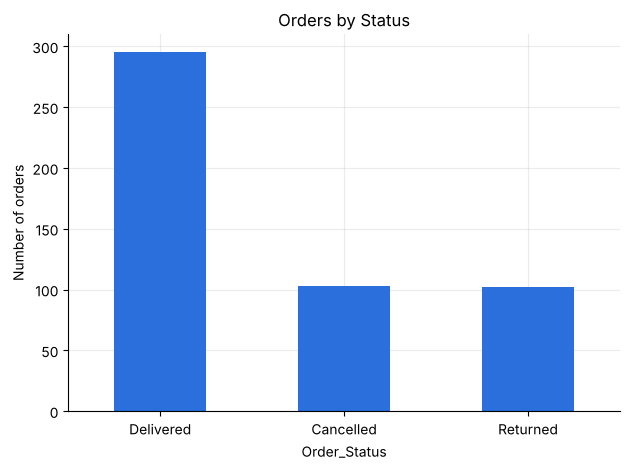

In [7]:
status_counts.plot(kind="bar", color=BLUE, title="Orders by Status", rot=0)
plt.ylabel("Number of orders")
plt.tight_layout()
plt.show()

In [8]:
# What do cancelled and returned orders do to sales and profit?
status_money = df_clean.groupby("Order_Status")[["Sales_INR", "Profit_INR"]].sum()
status_money

,Sales_INR,Profit_INR
Order_Status,,
Cancelled,0.0,0.00
Delivered,641565.5,103002.50
Returned,263535.5,-22489.25


### Insights: order status
- Only **59%** of orders (295 of 500) were delivered. **20.6%** were cancelled and **20.4%** were returned, so about 4 in 10 orders do not complete.
- **Cancelled** orders show ₹0 sales and ₹0 profit.
- **Returned** orders still carry **₹2.64 lakh** of recorded sales (29% of the ₹9.05 lakh total), but they produce a **loss of about ₹22.5K**.
- Because of this, the rest of the analysis uses **Delivered orders only**. Including returns would overstate revenue.

In [9]:
delivered = df_clean[df_clean["Order_Status"] == "Delivered"].copy()
print("Delivered orders:", len(delivered))

total_sales = delivered["Sales_INR"].sum()
total_profit = delivered["Profit_INR"].sum()
print("Total sales (INR):", total_sales)
print("Total profit (INR):", total_profit)
print("Overall profit margin %:", round(total_profit / total_sales * 100, 2))

Delivered orders: 295
Total sales (INR): 641565.5
Total profit (INR): 103002.5
Overall profit margin %: 16.05


**Delivered orders:** 295 orders, **₹6.42 lakh** sales, **₹1.03 lakh** profit, an overall margin of **16.05%**.

## 4. Region analysis

In [10]:
region_analysis = delivered.groupby("Region").agg(
    Total_Sales=("Sales_INR", "sum"),
    Total_Profit=("Profit_INR", "sum"),
    Total_Quantity=("Quantity", "sum")
)
region_analysis["Margin_%"] = (region_analysis["Total_Profit"] / region_analysis["Total_Sales"] * 100).round(2)
region_analysis = region_analysis.sort_values("Total_Sales", ascending=False)
region_analysis

,Total_Sales,Total_Profit,Total_Quantity,Margin_%
Region,,,,
West,163393.5,25038.5,163,15.32
Central,130714.5,19471.5,139,14.90
South,122770.5,17809.5,123,14.51
East,119749.0,22871.0,134,19.10
North,104938.0,17812.0,111,16.97


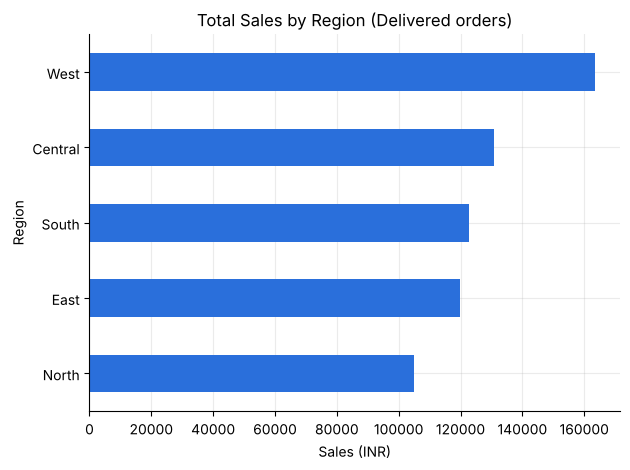

In [11]:
region_analysis["Total_Sales"].sort_values().plot(kind="barh", color=BLUE, title="Total Sales by Region (Delivered orders)")
plt.xlabel("Sales (INR)")
plt.ylabel("Region")
plt.tight_layout()
plt.show()

### Insights: region
- **West** leads in sales (₹1.63 lakh, about 25% of the total). **North** is lowest (₹1.05 lakh).
- **East** has the best profit margin at **19.1%**, even though it ranks fourth in sales. Central and South have the lowest margins (about 14.5% to 14.9%).
- Sales rank and margin rank are different, so growing West is not the same as growing profit. East is worth a closer look.

## 5. Category analysis

In [12]:
category_analysis = delivered.groupby("Category").agg(
    Total_Sales=("Sales_INR", "sum"),
    Total_Profit=("Profit_INR", "sum")
)
category_analysis["Margin_%"] = (category_analysis["Total_Profit"] / category_analysis["Total_Sales"] * 100).round(2)
category_analysis["Sales_Share_%"] = (category_analysis["Total_Sales"] / category_analysis["Total_Sales"].sum() * 100).round(1)
category_analysis["Profit_Share_%"] = (category_analysis["Total_Profit"] / category_analysis["Total_Profit"].sum() * 100).round(1)
category_analysis = category_analysis.sort_values("Total_Sales", ascending=False)
category_analysis

,Total_Sales,Total_Profit,Margin_%,Sales_Share_%,Profit_Share_%
Category,,,,,
Electronics,240200.0,35426.0,14.75,37.4,34.4
Fitness,165687.5,19138.5,11.55,25.8,18.6
Home & Living,133380.0,26691.0,20.01,20.8,25.9
Fashion,73750.0,14070.0,19.08,11.5,13.7
Stationery,28548.0,7677.0,26.89,4.4,7.5


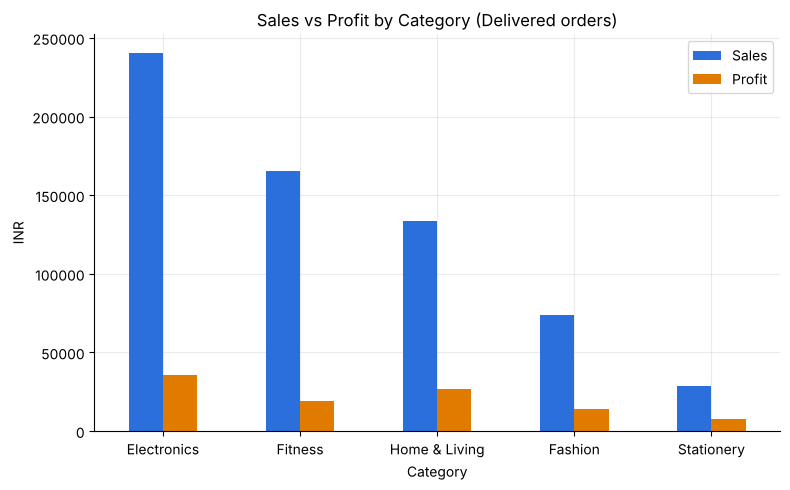

In [13]:
category_analysis[["Total_Sales", "Total_Profit"]].plot(
    kind="bar", figsize=(8, 5), color=[BLUE, ORANGE],
    title="Sales vs Profit by Category (Delivered orders)", rot=0
)
plt.ylabel("INR")
plt.legend(["Sales", "Profit"])
plt.tight_layout()
plt.show()

### Insights: category
- **Electronics** is the top category: **₹2.40 lakh** sales, 37% of the total, with a 14.7% margin.
- **Home & Living** makes 21% of sales but **26% of profit**, thanks to a **20.0%** margin.
- **Fitness** is the second-biggest category (₹1.66 lakh) but has a thin **11.6%** margin, so it brings 26% of sales and only 19% of profit.
- **Stationery** is the smallest category but has the best margin, **26.9%**.
- **Takeaway:** the best-selling category is not the most profitable one. Looking at sales alone can mislead.

## 6. Monthly sales trend

In [14]:
delivered["Month"] = delivered["Order_Date"].dt.to_period("M")
monthly_sales = delivered.groupby("Month")["Sales_INR"].sum()
monthly_sales

Month
2025-01    61515.5
2025-02    66587.0
2025-03    71277.0
2025-04    50067.5
2025-05    44050.0
2025-06    56584.5
2025-07    40441.5
2025-08    27605.0
2025-09    52417.5
2025-10    46307.0
2025-11    50393.0
2025-12    74320.0
Freq: M, Name: Sales_INR, dtype: float64

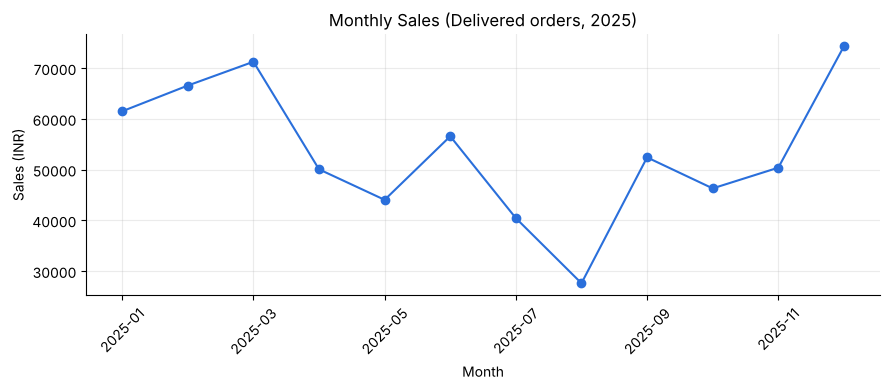

In [15]:
monthly_sales.index = monthly_sales.index.astype(str)
monthly_sales.plot(kind="line", marker="o", color=BLUE, figsize=(9, 4), title="Monthly Sales (Delivered orders, 2025)")
plt.ylabel("Sales (INR)")
plt.xlabel("Month")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### Insights: monthly trend
- Sales peaked in **December (₹74.3K)**, followed by **March (₹71.3K)**. January to March is strong overall.
- The lowest month was **August (₹27.6K)**, about **2.7 times lower** than the December peak. July was also weak (₹40.4K).
- Sales recovered in September (₹52.4K) and rose again towards the year end, which may point to festive or year-end demand.

## 7. Top products

In [16]:
product_analysis = delivered.groupby("Product").agg(
    Total_Sales=("Sales_INR", "sum"),
    Total_Profit=("Profit_INR", "sum")
)
product_analysis["Margin_%"] = (product_analysis["Total_Profit"] / product_analysis["Total_Sales"] * 100).round(1)
top_products = product_analysis.sort_values("Total_Sales", ascending=False).head(10)
top_products

,Total_Sales,Total_Profit,Margin_%
Product,,,
Running Shoes,121760.0,8928.0,7.3
Bluetooth Speaker,116400.0,14640.0,12.6
LED Desk Lamp,62370.0,9018.0,14.5
Hoodie,51600.0,8480.0,16.4
USB-C Hub,50320.0,7030.0,14.0
Keyboard,48000.0,8400.0,17.5
Storage Box,38780.0,8631.0,22.3
Water Bottle,32230.0,9042.0,28.1
Yoga Mat,31587.5,6982.5,22.1


Top 2 products share of total sales: 37.1%


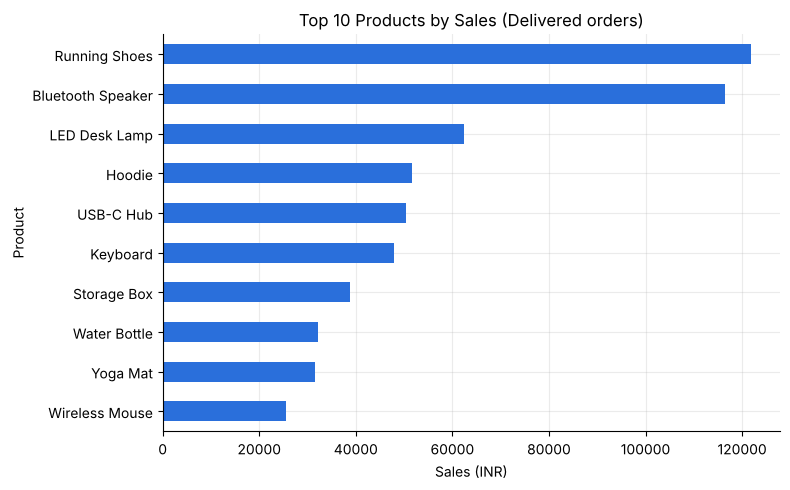

In [17]:
top_products["Total_Sales"].sort_values().plot(kind="barh", color=BLUE, figsize=(8, 5), title="Top 10 Products by Sales (Delivered orders)")
plt.xlabel("Sales (INR)")
plt.tight_layout()
plt.show()

top2_share = top_products["Total_Sales"].head(2).sum() / delivered["Sales_INR"].sum() * 100
print("Top 2 products share of total sales: %.1f%%" % top2_share)

### Insights: products
- **Running Shoes** (₹1.22 lakh) and **Bluetooth Speaker** (₹1.16 lakh) are the top two products and together make up **37%** of total sales. The business depends heavily on these two.
- The top seller, Running Shoes, has the **thinnest margin (7.3%)** among the top 10. Water Bottle sells much less but earns **28.1%** margin, and Storage Box earns 22.3%.

## 8. Discounts and profit

In [18]:
discount_analysis = delivered.groupby("Discount_Percent").agg(
    Orders=("Order_ID", "count"),
    Total_Sales=("Sales_INR", "sum"),
    Total_Profit=("Profit_INR", "sum")
)
discount_analysis["Margin_%"] = (discount_analysis["Total_Profit"] / discount_analysis["Total_Sales"] * 100).round(1)
discount_analysis

,Orders,Total_Sales,Total_Profit,Margin_%
Discount_Percent,,,,
0,82,166700.0,41523.0,24.9
5,57,137987.5,26677.5,19.3
10,74,153684.0,22938.0,14.9
15,48,94826.0,9711.0,10.2
20,34,88368.0,2153.0,2.4


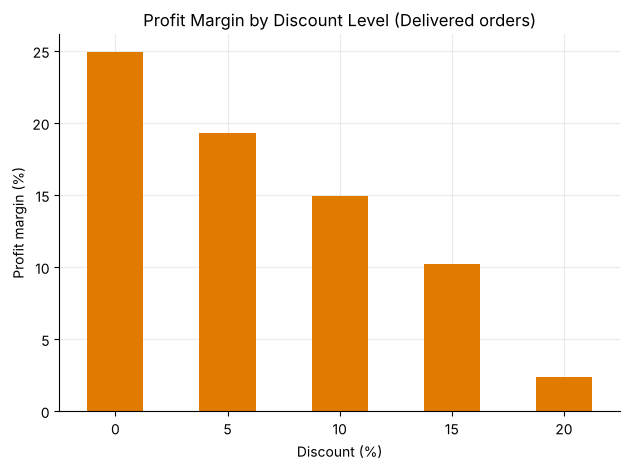

In [19]:
discount_analysis["Margin_%"].plot(kind="bar", color=ORANGE, title="Profit Margin by Discount Level (Delivered orders)", rot=0)
plt.xlabel("Discount (%)")
plt.ylabel("Profit margin (%)")
plt.tight_layout()
plt.show()

In [20]:
# Delivered orders that still lost money
delivered[delivered["Profit_INR"] < 0][["Product", "Discount_Percent", "Sales_INR", "Profit_INR"]]

,Product,Discount_Percent,Sales_INR,Profit_INR
14,Running Shoes,20,12800.0,-320.0
16,Running Shoes,20,7680.0,-192.0
118,Running Shoes,20,2560.0,-64.0
167,Running Shoes,20,7680.0,-192.0
205,Running Shoes,20,2560.0,-64.0
251,Running Shoes,20,5120.0,-128.0


### Insights: discounts
- Profit margin falls steadily as discount rises: about **24.9%** with no discount, **14.9%** at 10%, and only **2.4%** at 20%.
- Orders at 20% discount bring ₹88K in sales but just **₹2.2K** profit.
- All **6 loss-making delivered orders** are **Running Shoes sold at 20% discount**. This explains why the best-selling product has the lowest margin.
- **Suggestion:** cap discounts at about 10% (especially on Running Shoes) to protect profit.

## 9. Sales channel and customer segment

In [21]:
channel_sales = delivered.groupby("Sales_Channel")["Sales_INR"].sum().sort_values(ascending=False)
segment_sales = delivered.groupby("Customer_Segment")["Sales_INR"].sum().sort_values(ascending=False)

print((channel_sales / channel_sales.sum() * 100).round(1))
print()
print((segment_sales / segment_sales.sum() * 100).round(1))

Sales_Channel
Website        39.2
Marketplace    32.1
Mobile App     28.7
Name: Sales_INR, dtype: float64

Customer_Segment
Small Business    35.7
Corporate         35.6
Consumer          28.6
Name: Sales_INR, dtype: float64


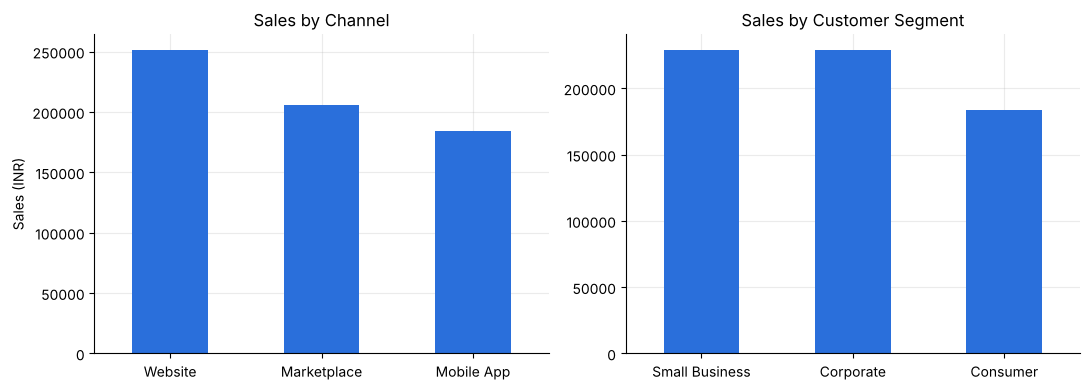

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
channel_sales.plot(kind="bar", color=BLUE, ax=axes[0], title="Sales by Channel", rot=0)
segment_sales.plot(kind="bar", color=BLUE, ax=axes[1], title="Sales by Customer Segment", rot=0)
axes[0].set_ylabel("Sales (INR)")
axes[0].set_xlabel("")
axes[1].set_xlabel("")
plt.tight_layout()
plt.show()

### Insights: channel and segment
- **Website** is the strongest channel (₹2.52 lakh, 39% of sales), ahead of Marketplace (32%) and Mobile App (29%).
- **Small Business** and **Corporate** customers each bring about 36% of sales. **Consumers** bring 29%, so business buyers matter more than individual shoppers.

## Key Findings
1. Of 500 orders, only **59% were delivered**. 20.6% were cancelled and 20.4% were returned. Returned orders caused a loss of about ₹22.5K.
2. Delivered orders gave **₹6.42 lakh sales and ₹1.03 lakh profit** (16.05% margin).
3. **Electronics** leads in sales (₹2.40 lakh), but **Home & Living** (20.0%) and **Stationery** (26.9%) earn much higher margins. **Fitness** sells well but has a thin 11.6% margin.
4. **West** leads in sales, while **East** has the best margin (19.1%).
5. Sales peak in **December and March** and drop sharply in **August**.
6. **Running Shoes and Bluetooth Speaker** make 37% of sales. Running Shoes has the lowest margin (7.3%).
7. **Discounts hurt profit**: margin drops from 24.9% (no discount) to 2.4% (20% discount). All loss-making delivered orders are Running Shoes at 20% discount.

### Recommendations
- Reduce cancellations and returns, because they affect about 4 in 10 orders.
- Limit discounts to around 10%, especially on Running Shoes.
- Push high-margin categories (Home & Living, Stationery) and look at what works in the East region.
- Plan stock and campaigns around the August slump and the December peak.